c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.1.0)/charset_normalizer (3.4.0) doesn't match a supported version!
  warnings.warn(


S&P 500: train 53.8%, test 16.4%, stocks used: 100
       distance   method  cluster  n  train_ret  test_ret  beat_train  beat_test
         1-corr     ward        1 21      2.030     0.331        True       True
sqrt(2(1-corr))     ward        2 13      1.713     0.434        True       True
sqrt(2(1-corr))     ward        1 12      1.238     0.399        True       True
sqrt(2(1-corr)) complete        6 18      1.073     0.177        True       True
         1-corr complete        6 18      1.073     0.177        True       True
         1-corr  average        4 50      0.791     0.235        True       True
sqrt(2(1-corr))  average        4 50      0.791     0.235        True       True
         1-corr     ward        3 18      0.679     0.104        True      False
sqrt(2(1-corr))     ward        3 22      0.637     0.088        True      False
         1-corr complete        4  9      0.587     0.062        True      False
sqrt(2(1-corr)) complete        4  9      0.587     0.062 

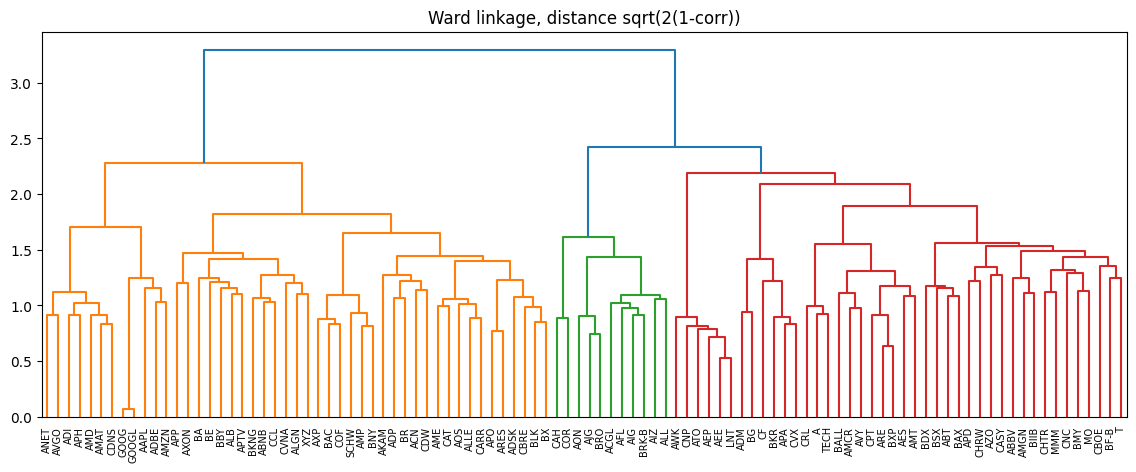

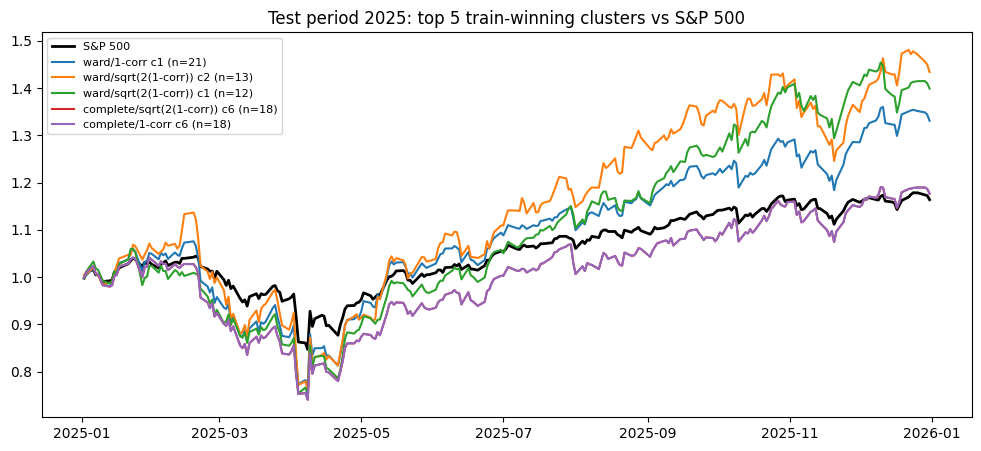


Best cluster members: ['AAPL', 'ABNB', 'ACN', 'ADBE', 'ADI', 'AKAM', 'ALGN', 'AMAT', 'AMD', 'AMZN', 'ANET', 'APH', 'APP', 'AVGO', 'AXON', 'BKNG', 'CCL', 'CDNS', 'CVNA', 'GOOG', 'GOOGL']


In [1]:
import pandas as pd, numpy as np, yfinance as yf, matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform

# 1. S&P 500 tickers from CSV (Yahoo uses "-" instead of ".", e.g. BRK-B)
sp = pd.read_csv("https://raw.githubusercontent.com/datasets/s-and-p-500-companies/main/data/constituents.csv")
tickers = sp["Symbol"].str.replace(".", "-", regex=False).tolist()[:100]   # first 100 tickers

# 2. Download prices: cluster on 2023-2024 (train), check 2025 (test)
px = yf.download(tickers + ["^GSPC"], start="2023-01-01", end="2026-01-01", auto_adjust=True, progress=False)["Close"]
px = px.dropna(axis=1, thresh=int(0.95 * len(px))).ffill().dropna()
ret = px.pct_change().dropna()
train, test = ret[:"2024-12-31"], ret["2025-01-01":]
stocks = [c for c in ret.columns if c != "^GSPC"]
perf = lambda r: (1 + r).prod() - 1                  # total return of a daily return series
mkt_train, mkt_test = perf(train["^GSPC"]), perf(test["^GSPC"])
print(f"S&P 500: train {mkt_train:.1%}, test {mkt_test:.1%}, stocks used: {len(stocks)}")

# 3. Hierarchical clustering with different distances and linkage methods
corr = train[stocks].corr()
dists = {"1-corr": 1 - corr, "sqrt(2(1-corr))": np.sqrt((2 * (1 - corr)).clip(lower=0))}
rows = []
for dname, D in dists.items():
    cond = squareform(D.values, checks=False)
    for method in ["single", "complete", "average", "ward"]:
        labels = fcluster(linkage(cond, method=method), 8, criterion="maxclust")
        for k in np.unique(labels):
            members = [s for s, l in zip(stocks, labels) if l == k]
            rows.append([dname, method, k, len(members),
                         perf(train[members].mean(axis=1)), perf(test[members].mean(axis=1)), members])
res = pd.DataFrame(rows, columns=["distance", "method", "cluster", "n", "train_ret", "test_ret", "members"])

# 4-5. Compare to S&P 500 and isolate clusters beating the market (in train), then check them in test
res["beat_train"] = res.train_ret > mkt_train
res["beat_test"] = res.test_ret > mkt_test
win = res[res.beat_train & (res.n >= 3)].sort_values("train_ret", ascending=False)
pd.set_option("display.width", 200, "display.max_colwidth", 60)
print(win.drop(columns="members").round(3).to_string(index=False))
print("\nShare of train winners that also beat the market in test:", f"{win.beat_test.mean():.0%}")

# Dendrogram for one setting
plt.figure(figsize=(14, 5))
dendrogram(linkage(squareform(dists["sqrt(2(1-corr))"].values, checks=False), "ward"), labels=stocks, leaf_font_size=7)
plt.title("Ward linkage, distance sqrt(2(1-corr))"); plt.show()

# Best clusters vs S&P 500 in the test period
plt.figure(figsize=(12, 5))
plt.plot((1 + test["^GSPC"]).cumprod(), "k", lw=2, label="S&P 500")
for _, r in win.head(5).iterrows():
    plt.plot((1 + test[r.members].mean(axis=1)).cumprod(), label=f"{r.method}/{r.distance} c{r.cluster} (n={r.n})")
plt.title("Test period 2025: top 5 train-winning clusters vs S&P 500"); plt.legend(fontsize=8); plt.show()
print("\nBest cluster members:", win.iloc[0].members)